# Creating Cohorts of Songs

Grouping 1,610 Rolling Stones tracks into five sonic cohorts from Spotify audio
features, to support music recommendation.

**What it found:** no audio feature predicts popularity, and the largest cohort, the
band's signature loud rock with 431 songs, contains no track above popularity 50.

**How:** standardised ten audio features, reduced with PCA, clustered with KMeans at k=5,
then validated against popularity and release year, which were never used as inputs.


### 1 Data loading and setup


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

RANDOM_STATE = 42

df = pd.read_csv('rolling_stones_spotify.csv')

print(f"Rows: {df.shape[0]}   Columns: {df.shape[1]}")
df.head()

Rows: 1610   Columns: 18


,Unnamed: 0,name,album,release_date,track_number,id,uri,acousticness,danceability,energy,instrumentalness,liveness,loudness,speechiness,tempo,valence,popularity,duration_ms
0,0,Concert Intro Music - Live,Licked Live In NYC,2022-06-10,1,2IEkywLJ4ykbhi1yRQvmsT,spotify:track:2IEkywLJ4ykbhi1yRQvmsT,0.0824,0.463,0.993,0.996000,0.932,-12.913,0.1100,118.001,0.0302,33,48640
1,1,Street Fighting Man - Live,Licked Live In NYC,2022-06-10,2,6GVgVJBKkGJoRfarYRvGTU,spotify:track:6GVgVJBKkGJoRfarYRvGTU,0.4370,0.326,0.965,0.233000,0.961,-4.803,0.0759,131.455,0.3180,34,253173
2,2,Start Me Up - Live,Licked Live In NYC,2022-06-10,3,1Lu761pZ0dBTGpzxaQoZNW,spotify:track:1Lu761pZ0dBTGpzxaQoZNW,0.4160,0.386,0.969,0.400000,0.956,-4.936,0.1150,130.066,0.3130,34,263160
3,3,If You Can't Rock Me - Live,Licked Live In NYC,2022-06-10,4,1agTQzOTUnGNggyckEqiDH,spotify:track:1agTQzOTUnGNggyckEqiDH,0.5670,0.369,0.985,0.000107,0.895,-5.535,0.1930,132.994,0.1470,32,305880
4,4,Don’t Stop - Live,Licked Live In NYC,2022-06-10,5,7piGJR8YndQBQWVXv6KtQw,spotify:track:7piGJR8YndQBQWVXv6KtQw,0.4000,0.303,0.969,0.055900,0.966,-5.098,0.0930,130.533,0.2060,32,305106


### 2.1 Data inspection — structure, duplicates, missing values

Four checks: duplicates, missing values, erroneous entries and outliers.



In [2]:
print("-- Structure / dtypes --")
df.info()

print("\n-- Duplicates --")
print("Fully duplicated rows:  ", df.duplicated().sum())
print("Duplicated Spotify IDs: ", df['id'].duplicated().sum())
print("Duplicated song names:  ", df['name'].duplicated().sum())

print("\n-- Missing values --")
missing = df.isnull().sum().sort_values(ascending=False)
print(missing[missing > 0] if (missing > 0).any() else "None")


-- Structure / dtypes --
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1610 entries, 0 to 1609
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Unnamed: 0        1610 non-null   int64  
 1   name              1610 non-null   object 
 2   album             1610 non-null   object 
 3   release_date      1610 non-null   object 
 4   track_number      1610 non-null   int64  
 5   id                1610 non-null   object 
 6   uri               1610 non-null   object 
 7   acousticness      1610 non-null   float64
 8   danceability      1610 non-null   float64
 9   energy            1610 non-null   float64
 10  instrumentalness  1610 non-null   float64
 11  liveness          1610 non-null   float64
 12  loudness          1610 non-null   float64
 13  speechiness       1610 non-null   float64
 14  tempo             1610 non-null   float64
 15  valence           1610 non-null   float64
 16  popularity       

**2.1 Finding**

Nothing is missing. Every song has a value in every column.
No song is listed twice, and no track ID repeats.

But 656 songs share a name with another song. Checked next.



### 2.2 Distribution and scale check

Examines the range of every numeric column. This is where erroneous entries and
the scale of each feature become visible before any modelling.


In [3]:
print(df.describe().T[['min', '25%', '50%', '75%', 'max']].round(3))

print("\n-- Popularity spread --")
print("Songs with popularity = 0:", (df['popularity'] == 0).sum())
print("Songs with popularity >= 50:", (df['popularity'] >= 50).sum())


                        min         25%         50%         75%         max
Unnamed: 0            0.000     402.250     804.500    1206.750    1609.000
track_number          1.000       4.000       7.000      11.000      47.000
acousticness          0.000       0.058       0.183       0.404       0.994
danceability          0.104       0.362       0.458       0.578       0.887
energy                0.141       0.674       0.848       0.945       0.999
instrumentalness      0.000       0.000       0.014       0.179       0.996
liveness              0.022       0.153       0.380       0.894       0.998
loudness            -24.408      -8.982      -6.523      -4.609      -1.014
speechiness           0.023       0.036       0.051       0.087       0.624
tempo                46.525     107.391     124.404     142.356     216.304
valence               0.000       0.404       0.583       0.778       0.974
popularity            0.000      13.000      20.000      27.000      80.000
duration_ms 

**2.2 Finding**

Nothing needs rescaling and only 43 of 1,610 songs reach popularity 50.

Tempo runs 46.5 to 216.3 BPM and loudness −24.4 to −1.0 dB, both inside the ranges Spotify documents. Popularity runs 0 to 80 and half the songs score 20 or less.


## Section 2 summary

The data is clean. No missing values, no repeated rows or IDs, and the audio
features are already on the right scale. The only thing to look at is the 656 songs that share a name with another song, that comes next.


### 3.1 Cleaning — index column and date type

Two structural fixes: remove the exported index and convert release_date to a real date so a release year can be derived.


In [4]:
df = df.drop(columns=['Unnamed: 0'])

df['release_date'] = pd.to_datetime(df['release_date'])
df['release_year'] = df['release_date'].dt.year
df['duration_min'] = df['duration_ms'] / 60_000

print("Shape after dropping index:", df.shape)
print("Date range:", df['release_date'].min().date(), "to", df['release_date'].max().date())
print("Release years covered:", df['release_year'].nunique())
print("\nDtypes now:")
print(df[['release_date', 'release_year', 'duration_min']].dtypes)


Shape after dropping index: (1610, 19)
Date range: 1964-04-16 to 2022-06-10
Release years covered: 35

Dtypes now:
release_date    datetime64[ns]
release_year             int32
duration_min           float64
dtype: object


**3.1 Finding**

The extra index column is dropped. 1,610 songs, 19 columns now.

The date is now a real date. Range: April 1964 to June 2022. That is 35 release years.


### 3.2 Cleaning — investigating the repeated song names

656 rows share a song name. This cell checks whether they are data errors or separate recordings before deciding whether to keep them.


In [5]:
dupe_names = df[df.duplicated('name', keep=False)]

print(f"Rows involved in a duplicated name: {len(dupe_names)}")
print(f"Unique names affected:              {dupe_names['name'].nunique()}")

print("\nDistinct albums per duplicated name:")
print(dupe_names.groupby('name')['album'].nunique().describe().round(2))

print("\nMost-repeated songs:")
for song, n in (dupe_names.groupby('name')['album'].nunique()
                .sort_values(ascending=False).head(3).items()):
    print(f"\n  {song}  —  {n} albums")
    for alb in dupe_names[dupe_names['name'] == song]['album'].unique():
        print("     -", alb)


Rows involved in a duplicated name: 969
Unique names affected:              313

Distinct albums per duplicated name:
count    313.00
mean       2.77
std        1.94
min        1.00
25%        2.00
50%        2.00
75%        3.00
max       15.00
Name: album, dtype: float64

Most-repeated songs:

  Brown Sugar - Live  —  15 albums
     - Licked Live In NYC
     - A Bigger Bang (Live)
     - Steel Wheels Live
     - Bridges To Buenos Aires (Live)
     - Bridges To Bremen (Live)
     - Voodoo Lounge Uncut (Live)
     - From The Vault: No Security - San Jose 1999 (Live)
     - Sticky Fingers Live At The Fonda Theatre
     - Ladies & Gentlemen (Live)
     - Havana Moon (Live)
     - Totally Stripped - Brixton (Live)
     - Totally Stripped (Live)
     - Totally Stripped - Paris (Live)
     - Some Girls: Live In Texas '78
     - Love You Live (Remastered)

  Honky Tonk Women - Live  —  15 albums
     - Licked Live In NYC
     - A Bigger Bang (Live)
     - Steel Wheels Live
     - Bridges To 

**3.2 Finding**

969 rows are involved in duplicated song names, representing 313 unique songs appearing on multiple albums — about 2.8 albums each on average.

"Brown Sugar - Live" is on 15 albums. "Honky Tonk Women - Live" is on 15 too. Get Yer Ya-Ya's Out! appears under three different edition names.

These are different live recordings and remasters, not copied rows. Each has its own track ID. Deleting them would remove 60% of the data.

So all 1,610 songs stay.


### 3.3 Cleaning — duration check and final confirmation

The longest tracks are checked here because they sit far from the median, then the cleaned dataset is confirmed.


In [6]:
print("Duration in minutes:")
print(df['duration_min'].describe().round(2))

print("\nLongest tracks:")
print(df.nlargest(5, 'duration_min')[['name', 'album', 'duration_min']])

print("\nShortest tracks:")
print(df.nsmallest(3, 'duration_min')[['name', 'album', 'duration_min']])

print("\n-- Final check --")
print("Shape:", df.shape,
      "| missing:", df.isnull().sum().sum(),
      "| dup IDs:", df['id'].duplicated().sum())


Duration in minutes:
count    1610.00
mean        4.30
std         1.81
min         0.35
25%         3.18
50%         4.05
75%         4.92
max        16.36
Name: duration_min, dtype: float64

Longest tracks:
                        name                              album  duration_min
220          Miss You - Live           Bridges To Bremen (Live)     16.364433
460  Midnight Rambler - Live                 Havana Moon (Live)     15.490950
537          Miss You - Live    Totally Stripped - Paris (Live)     15.122883
482          Miss You - Live  Totally Stripped - Brixton (Live)     13.866000
297          Miss You - Live         Voodoo Lounge Uncut (Live)     13.598117

Shortest tracks:
                                                  name                                              album  duration_min
546                                  Show Intro - Live  Live 1965: Music From Charlie Is My Darling (L...      0.350000
839  Intro (Take The A Train) - Live / Remastered 2009           

**3.3 Finding**

No rows were removed, so 1,610 remain with no missing values and no repeated IDs.

Durations run from 21 seconds to 16.4 minutes, with a median of 4.05. The longest are live versions of "Miss You" and "Midnight Rambler", songs the band plays much longer on stage. Real music, not bad data.


### 3.4 Outlier check

Every numeric feature is checked for values beyond 1.5 times the interquartile range.

In [7]:
num_cols = ['acousticness', 'danceability', 'energy', 'instrumentalness',
            'liveness', 'loudness', 'speechiness', 'tempo', 'valence', 'duration_min']

rows = []
for col in num_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df[col] < lo) | (df[col] > hi)).sum()
    rows.append({'feature': col, 'lower': round(lo, 2), 'upper': round(hi, 2),
                 'outliers': n_out, 'pct': round(n_out / len(df) * 100, 1)})

outliers = pd.DataFrame(rows).sort_values('pct', ascending=False)
print(outliers.to_string(index=False))


         feature  lower  upper  outliers  pct
instrumentalness  -0.27   0.45       272 16.9
     speechiness  -0.04   0.16        92  5.7
    duration_min   0.56   7.54        76  4.7
           tempo  54.94 194.80        34  2.1
        loudness -15.54   1.95        14  0.9
          energy   0.27   1.35         8  0.5
    acousticness  -0.46   0.92         4  0.2
    danceability   0.04   0.90         0  0.0
        liveness  -0.96   2.00         0  0.0
         valence  -0.16   1.34         0  0.0


**3.4 Finding**

An IQR check flags values beyond 1.5 times the interquartile range on every numeric feature. Instrumentalness has by far the most, at 272 songs (16.9%), followed by speechiness at 92 (5.7%) and duration at 76 (4.7%). Tempo has 34, loudness 14, energy 8 and acousticness 4. Danceability, liveness and valence have none.

None were removed. The high instrumentalness count is not a data problem: 75% of songs score below 0.179 on that feature, so the middle of the distribution sits near zero and anything in the instrumental range falls outside the bounds. The same applies to speechiness and duration, where the flagged songs are quiet acoustic tracks, live jams and instrumentals rather than errors.


## Section 3 summary

The data came in good shape, so cleaning was simple. No missing values, no repeated track IDs, and the features were already on the right scale.

Two small fixes: dropped the index column, converted the date to a real date.

The one real question was the 656 repeated song names. They are separate live recordings and remasters, so all rows stay. Same for the longest tracks. Nothing was removed.


## 4. Exploratory Data Analysis

### 4.1 Distribution of song popularity

Popularity runs 0 to 80 in this dataset. Its shape decides how "popular song" is defined in the album analysis.



count    1610.00
mean       20.79
std        12.43
min         0.00
25%        13.00
50%        20.00
75%        27.00
max        80.00
Name: popularity, dtype: float64


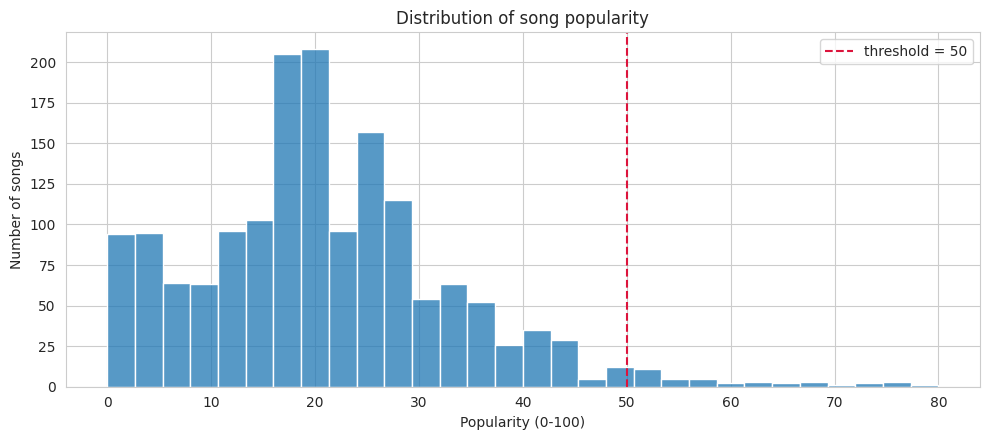

In [8]:
print(df['popularity'].describe().round(2))

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.histplot(df['popularity'], bins=30, ax=ax)
ax.axvline(50, color='crimson', ls='--', label='threshold = 50')
ax.set_title('Distribution of song popularity')
ax.set_xlabel('Popularity (0-100)')
ax.set_ylabel('Number of songs')
ax.legend()
plt.tight_layout()
plt.show()


**4.1 Finding**

Popularity is uneven. Half the songs score 20 or less, and the chart peaks around 15 to 22, then falls away quickly.

Only 43 songs out of 1,610 reach 50, about 3% of the catalogue.

So "popular" means a score of 50 or higher. That keeps roughly the top 3% and captures the songs with sustained streaming activity.

The album comparison that follows is run three ways so the answer can be checked against more than one definition.


### 4.2 Which albums to recommend?

Popularity is treated as a binary here: a song is popular when its score is 50 or above, which captures the top 3% of the catalogue. The album comparison is run three ways, mean popularity, count of songs above 50, and percentage above 50, to check whether the recommendation holds under more than one definition.


In [9]:
POPULAR_THRESHOLD = 50

album_stats = df.groupby('album').agg(
    n_songs=('name', 'size'),
    mean_popularity=('popularity', 'mean'),
    max_popularity=('popularity', 'max'),
    n_popular=('popularity', lambda s: (s >= POPULAR_THRESHOLD).sum())
).round(2)

album_stats['pct_popular'] = (album_stats['n_popular'] / album_stats['n_songs'] * 100).round(1)

print(f"Distinct album labels: {len(album_stats)}\n")

print("Top 8 by MEAN popularity")
print(album_stats.sort_values('mean_popularity', ascending=False).head(8))

print(f"\nTop 8 by COUNT of songs >= {POPULAR_THRESHOLD}")
print(album_stats.sort_values('n_popular', ascending=False).head(8))

print("\nTop 8 by % of songs popular (albums with at least 8 songs)")
print(album_stats[album_stats['n_songs'] >= 8]
      .sort_values('pct_popular', ascending=False).head(8))


Distinct album labels: 90

Top 8 by MEAN popularity
                                            n_songs  mean_popularity  max_popularity  n_popular  pct_popular
album                                                                                                       
Sticky Fingers (Remastered)                      10            53.30              69          6         60.0
Some Girls                                       10            48.10              72          3         30.0
Tattoo You (2009 Re-Mastered)                    11            46.45              76          3         27.3
Exile On Main Street (2010 Re-Mastered)          18            44.17              63          4         22.2
Beggars Banquet (50th Anniversary Edition)       10            43.70              73          2         20.0
Aftermath                                        11            43.09              80          2         18.2
Goats Head Soup (Remastered 2009)                10            40.30        

**4.2 Finding**

Sticky Fingers (Remastered) has the highest average popularity at 53.30 and the highest share of popular tracks at 60%. First choice.

Second place depends on how you count. By average and by share: Some Girls (48.10, 30%). By count of popular songs: Exile On Main Street (4 songs).

Exile On Main Street has 18 tracks and 4 popular songs. Sticky Fingers has 10 tracks and 6. Counting hits alone favours long albums, so share is the fairer measure.

Recommended: Sticky Fingers (Remastered) and Some Girls.

Note: the 90 album labels include several editions of the same record, so numbers are per release, not per studio album.


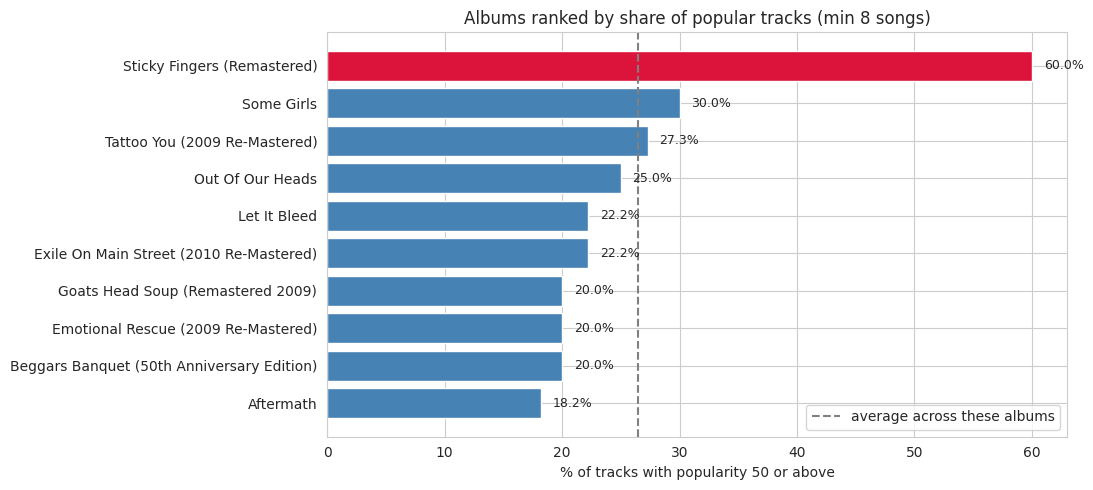

In [10]:
top = album_stats[album_stats['n_songs'] >= 8].sort_values('pct_popular', ascending=False).head(10)

fig, ax = plt.subplots(figsize=(11, 5))
bars = ax.barh(top.index[::-1], top['pct_popular'][::-1],
               color=['crimson' if i == top.index[0] else 'steelblue' for i in top.index[::-1]])
ax.set_xlabel('% of tracks with popularity 50 or above')
ax.set_title('Albums ranked by share of popular tracks (min 8 songs)')
ax.axvline(top['pct_popular'].mean(), color='grey', ls='--', label='average across these albums')
ax.legend()

for bar, val in zip(bars, top['pct_popular'][::-1]):
    ax.text(val + 1, bar.get_y() + bar.get_height()/2, f'{val}%', va='center', fontsize=9)

plt.tight_layout()
plt.show()


**4.2 Chart**

The chart ranks albums by the share of their tracks above popularity 50, keeping only albums with at least 8 songs so short records do not skew the ranking.

Sticky Fingers (Remastered) leads at 60%, more than double the next album. The dashed line marks the average across the ten albums shown, and four of them sit above it.


### 4.3 Popularity over time

Release year against mean popularity, checked for a trend.


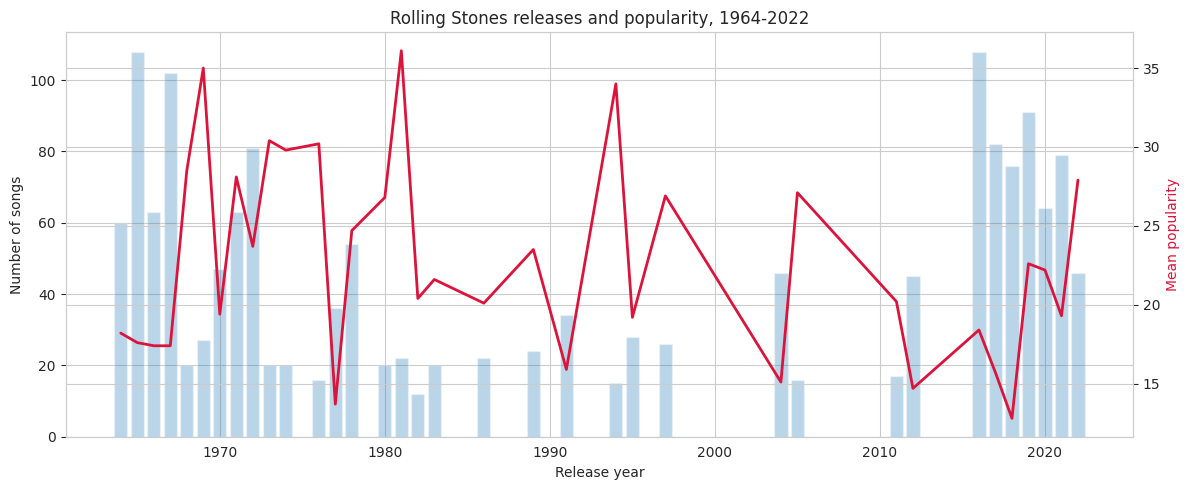

Years with no release: 24
[1975, 1979, 1984, 1985, 1987, 1988, 1990, 1992, 1993, 1996, 1998, 1999, 2000, 2001, 2002, 2003, 2006, 2007, 2008, 2009, 2010, 2013, 2014, 2015]


In [11]:
yearly = df.groupby('release_year').agg(
    n=('popularity', 'size'),
    mean_pop=('popularity', 'mean')
).round(1)

fig, ax1 = plt.subplots(figsize=(12, 5))
ax1.bar(yearly.index, yearly['n'], alpha=0.3, label='Songs released')
ax1.set_xlabel('Release year')
ax1.set_ylabel('Number of songs')

ax2 = ax1.twinx()
ax2.plot(yearly.index, yearly['mean_pop'], color='crimson', lw=2, label='Mean popularity')
ax2.set_ylabel('Mean popularity', color='crimson')

plt.title('Rolling Stones releases and popularity, 1964-2022')
plt.tight_layout()
plt.show()

full = yearly.reindex(range(df['release_year'].min(), df['release_year'].max() + 1))
print("Years with no release:", full['n'].isna().sum())
print(full[full['n'].isna()].index.tolist())


In [12]:
from numpy.polynomial import polynomial as P
import numpy.polynomial.polynomial as poly

coefs = np.polyfit(yearly.index, yearly['mean_pop'], 1)
print(f"Slope per year: {coefs[0]:.4f}")
print(f"Over 58 years that is a change of {coefs[0] * 58:.2f} popularity points")


Slope per year: -0.0825
Over 58 years that is a change of -4.78 popularity points


**4.3 Finding**

Popularity does not rise or fall over the years. It moves between 13 and 36 with no clear direction. A straight line through it slopes down by only 0.08 points a year, tiny next to the year-to-year swings.

Years with many songs are also years with reissues, and those years have lower average popularity. The 108 songs from 1965 are mostly old recordings re-released, and the tall bars from 2018 to 2022 come from the Tattoo You and Sticky Fingers deluxe editions.

So this chart shows what was re-released, not how the music has aged.

The span is 58 years, and counting both 1964 and 2022 makes 59 calendar years. 24 of those 59 have no release at all. Real gaps, not missing data.

### 4.4 Correlation between audio features and popularity

Checks how much the audio features overlap with each other, and whether any of them relates to popularity.


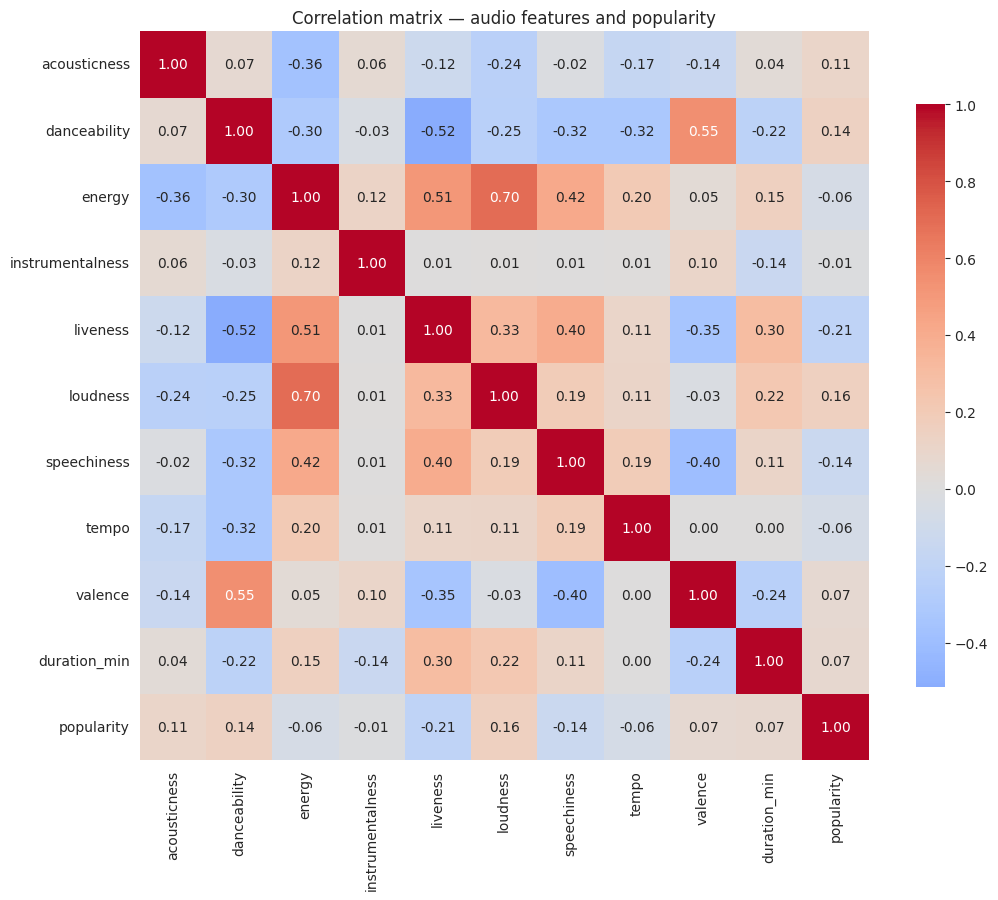

Correlation with popularity:
loudness            0.156
danceability        0.141
acousticness        0.108
duration_min        0.074
valence             0.065
instrumentalness   -0.011
energy             -0.057
tempo              -0.061
speechiness        -0.137
liveness           -0.206
Name: popularity, dtype: float64


In [13]:
audio_features = ['acousticness', 'danceability', 'energy', 'instrumentalness',
                  'liveness', 'loudness', 'speechiness', 'tempo', 'valence',
                  'duration_min', 'popularity']

corr = df[audio_features].corr()

plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            square=True, cbar_kws={'shrink': .8})
plt.title('Correlation matrix — audio features and popularity')
plt.tight_layout()
plt.show()

print("Correlation with popularity:")
print(corr['popularity'].drop('popularity').sort_values(ascending=False).round(3))


**4.4 Finding**

Some features measure the same thing. Energy and loudness move together at +0.70. Five other pairs are above 0.35, like danceability and valence at +0.55.

So the ten features are not ten separate qualities, the same things are measured more than once. That is why we reduce them next.

Nothing relates to popularity. The strongest link is liveness at −0.21 and everything else is under ±0.16. No audio feature shows more than a weak link to popularity.

So popularity stays out of the clustering, and is only used afterwards to check.


## 5. Dimensionality Reduction and Clustering

### 5.1 Standardising the audio features

The ten audio features are rescaled before PCA and clustering so that each contributes
equally. Both methods measure distance between songs, so without this a feature with a
wide spread would dominate every calculation.


## Section 4 summary

Sticky Fingers (Remastered) and Some Girls are the two albums to recommend. Sticky Fingers leads every measure; Some Girls is second on average and on share.

Popularity does not change over time, and it does not relate to any audio feature.


In [14]:
cluster_features = ['acousticness', 'danceability', 'energy', 'instrumentalness',
                    'liveness', 'loudness', 'speechiness', 'tempo', 'valence',
                    'duration_min']

X = df[cluster_features].copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Before scaling — standard deviation per feature:")
print(X.std().round(3))
print("\nAfter scaling — standard deviation per feature:")
print(pd.DataFrame(X_scaled, columns=cluster_features).std().round(3))


Before scaling — standard deviation per feature:
acousticness         0.227
danceability         0.142
energy               0.180
instrumentalness     0.276
liveness             0.349
loudness             2.994
speechiness          0.052
tempo               29.233
valence              0.231
duration_min         1.806
dtype: float64

After scaling — standard deviation per feature:
acousticness        1.0
danceability        1.0
energy              1.0
instrumentalness    1.0
liveness            1.0
loudness            1.0
speechiness         1.0
tempo               1.0
valence             1.0
duration_min        1.0
dtype: float64


**5.1 Finding**

The features are on very different scales. Tempo has a standard deviation of 29.23 and loudness 2.99, while speechiness is 0.052 and danceability 0.142, a spread of roughly 560 times between the widest and narrowest.

Both PCA and KMeans measure distance between songs. Without rescaling, tempo alone would control every calculation and the other nine features would have almost no effect on which songs group together.

After standardisation every feature has a standard deviation of 1.0. All clustering below uses the scaled data.


### 5.2 Principal component analysis

Reduces the ten correlated audio features to the components that carry most of the variation, so the overlap found in the correlation step is handled before clustering.


Explained variance per component:
  PC1:  30.3%   cumulative:  30.3%
  PC2:  16.5%   cumulative:  46.8%
  PC3:  11.3%   cumulative:  58.2%
  PC4:  10.5%   cumulative:  68.7%
  PC5:   8.2%   cumulative:  76.8%
  PC6:   7.3%   cumulative:  84.1%
  PC7:   6.1%   cumulative:  90.2%
  PC8:   5.2%   cumulative:  95.4%
  PC9:   2.9%   cumulative:  98.3%
  PC10:   1.7%   cumulative: 100.0%

Components needed for 80% of variance: 6


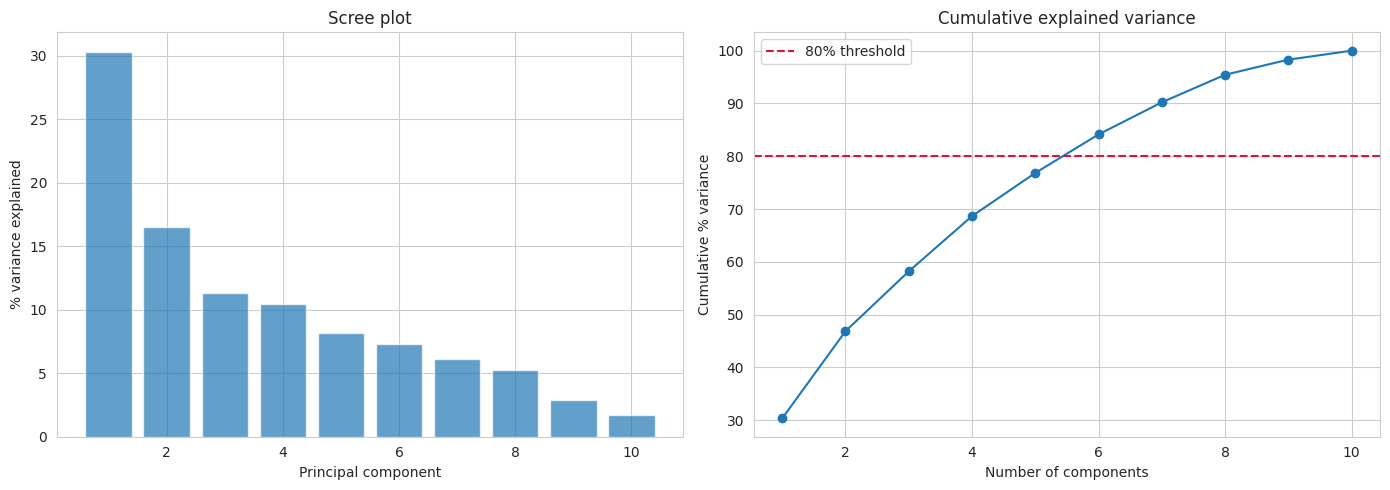


Loadings for the first three components:
                   PC1   PC2   PC3
liveness          0.44 -0.09 -0.06
energy            0.43  0.41 -0.05
danceability     -0.41  0.25 -0.22
loudness          0.36  0.35 -0.26
speechiness       0.36 -0.15  0.22
valence          -0.27  0.57 -0.05
duration_min      0.23 -0.22 -0.53
tempo             0.20  0.13  0.45
acousticness     -0.16 -0.46  0.09
instrumentalness  0.00  0.16  0.58


In [15]:
pca = PCA()
X_pca = pca.fit_transform(X_scaled)

explained = pca.explained_variance_ratio_
cumulative = np.cumsum(explained)

print("Explained variance per component:")
for i, (e, c) in enumerate(zip(explained, cumulative), 1):
    print(f"  PC{i}: {e*100:5.1f}%   cumulative: {c*100:5.1f}%")

print(f"\nComponents needed for 80% of variance: {np.argmax(cumulative >= 0.80) + 1}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(range(1, len(explained)+1), explained*100, alpha=0.7)
axes[0].set_xlabel('Principal component')
axes[0].set_ylabel('% variance explained')
axes[0].set_title('Scree plot')

axes[1].plot(range(1, len(cumulative)+1), cumulative*100, marker='o')
axes[1].axhline(80, color='crimson', ls='--', label='80% threshold')
axes[1].set_xlabel('Number of components')
axes[1].set_ylabel('Cumulative % variance')
axes[1].set_title('Cumulative explained variance')
axes[1].legend()
plt.tight_layout()
plt.show()

loadings = pd.DataFrame(pca.components_[:3].T,
                        columns=['PC1', 'PC2', 'PC3'],
                        index=cluster_features).round(2)
print("\nLoadings for the first three components:")
print(loadings.sort_values('PC1', key=abs, ascending=False))


**5.2 Finding**

Ten features were reduced to their main components. PC1 explains 30.3%, PC2 16.5%, PC3 11.3%. Six components reach 80%.

So the ten features really describe about five or six qualities.

The scree plot falls smoothly with no clear break, so six is set by the 80% rule rather than an obvious gap.

What they mean: PC1 contrasts live, loud, spoken tracks against danceable ones. PC2 is positivity, happier, less acoustic, more energetic. PC3 is instrumental, and instrumental tracks also run longer.


### Why dimensionality reduction matters here

The correlation step showed that several audio features measure much the same thing. Energy and loudness move together at 0.70, and five other pairs sit above 0.35. When features overlap like that, they carry less information than their number suggests, and a model that treats them as ten separate measurements gives extra weight to whatever is duplicated.

PCA makes that overlap visible. Six components are enough to explain 80% of the variation, which means the ten features are really describing five or six underlying qualities. For a clustering problem this matters in two ways: it shows the input was not as rich as it first appeared, and it confirms the redundancy is real rather than accidental.

Reduction was not used as model input in the end. The clustering kept the original ten scaled features, because a cohort described by a component score cannot be explained to anyone. Saying a song sits at PC1 = 2.4 means nothing; saying it has an acousticness of 0.51 does. So PCA was used to understand the structure, and the interpretable features were used to build the cohorts.


## Section 5 summary

Six components explain 80% of the variation, so the ten audio features describe about five or six real qualities rather than ten.

PCA was used to see that structure, but the clustering itself used the ten scaled features so each group can be described in musical terms.


## 6. Cluster Analysis

### 6.1 Choosing the number of clusters

Two methods are compared: the elbow curve, which is read visually, and the silhouette score, which gives a number.


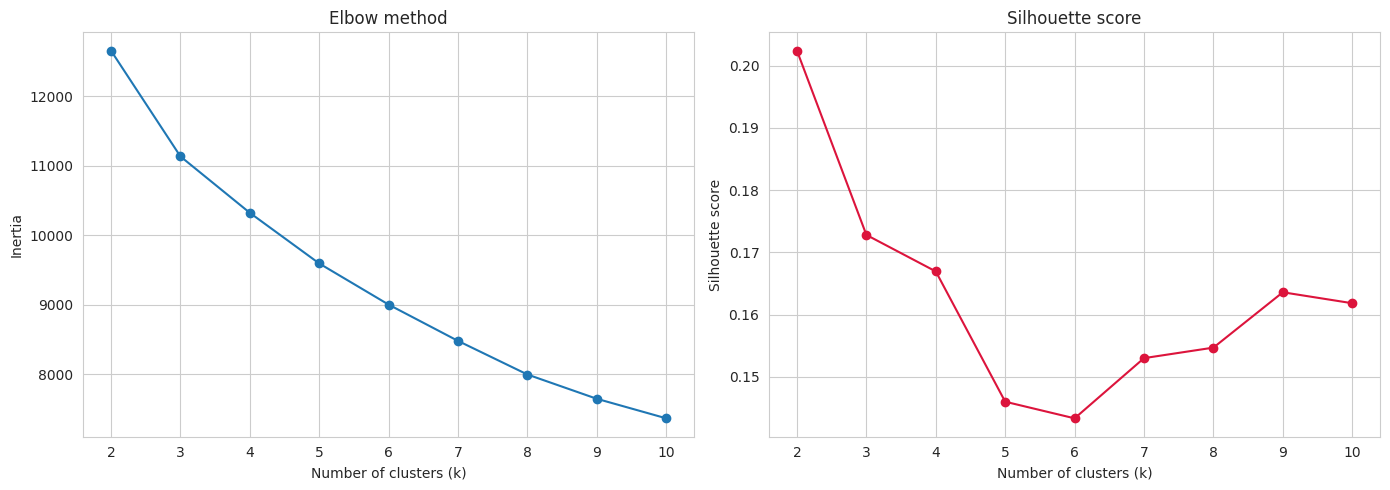

    k    inertia  silhouette
0   2  12657.607       0.202
1   3  11134.928       0.173
2   4  10322.584       0.167
3   5   9593.345       0.146
4   6   9000.636       0.143
5   7   8477.918       0.153
6   8   7993.979       0.155
7   9   7644.331       0.164
8  10   7363.153       0.162


In [16]:
k_range = range(2, 11)
inertia, silhouette = [], []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertia.append(km.inertia_)
    silhouette.append(silhouette_score(X_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(k_range, inertia, marker='o')
axes[0].set_xlabel('Number of clusters (k)')
axes[0].set_ylabel('Inertia')
axes[0].set_title('Elbow method')

axes[1].plot(k_range, silhouette, marker='o', color='crimson')
axes[1].set_xlabel('Number of clusters (k)')
axes[1].set_ylabel('Silhouette score')
axes[1].set_title('Silhouette score')

plt.tight_layout()
plt.show()

print(pd.DataFrame({'k': list(k_range), 'inertia': inertia,
                    'silhouette': silhouette}).round(3))


**6.1 Finding**

The elbow curve falls smoothly from k=2 to k=10 with no bend, so it cannot pick a number on its own.

The silhouette score is highest at k=2 (0.202) and lowest at k=6 (0.143).

k=2 was not chosen. With 1,610 songs, two groups would just be loud and quiet, the cleanest split, but far too broad to recommend anything from.

k=5 was chosen because it produced five cohorts that could each be described by their features. The next step shows what they are.


### 6.2 Fitting the model and profiling the cohorts

KMeans is fitted with k=5, then each cluster is profiled on the original audio features so the cohorts can be described in their own units.


In [17]:
K = 5
kmeans = KMeans(n_clusters=K, random_state=RANDOM_STATE, n_init=10)
df['cluster'] = kmeans.fit_predict(X_scaled)

print("Cluster sizes:")
print(df['cluster'].value_counts().sort_index())

print(f"\nFinal inertia: {kmeans.inertia_:,.0f}")
print(f"Silhouette:    {silhouette_score(X_scaled, df['cluster']):.3f}")

profile = df.groupby('cluster')[cluster_features].mean().round(3)
print("\nCluster profile — mean feature values:")
print(profile.T)


Cluster sizes:
cluster
0    332
1    431
2    180
3    256
4    411
Name: count, dtype: int64

Final inertia: 9,593
Silhouette:    0.146

Cluster profile — mean feature values:
cluster                 0        1        2        3        4
acousticness        0.242    0.198    0.258    0.511    0.148
danceability        0.615    0.346    0.494    0.431    0.492
energy              0.644    0.931    0.846    0.571    0.881
instrumentalness    0.073    0.123    0.770    0.087    0.063
liveness            0.201    0.867    0.437    0.350    0.446
loudness           -9.750   -5.269   -6.542   -9.231   -5.294
speechiness         0.048    0.119    0.056    0.048    0.055
tempo             120.555  138.860  127.493  108.890  127.238
valence             0.741    0.403    0.717    0.373    0.712
duration_min        3.228    5.417    3.436    4.669    4.126


**6.2 Finding**

Five groups: 332, 431, 180, 256 and 411 songs. Silhouette 0.146.

Group 1 (431): loudest and most energetic, energy 0.931, loudness −5.27, longest at 5.42 minutes.

Group 4 (411): energy 0.881, liveness 0.446. Live tracks, calmer than group 1.

Group 0 (332): most danceable (0.615) and most positive (0.741), shortest at 3.23 minutes.

Group 3 (256): highest acousticness (0.511), lowest energy, slowest tempo, lowest mood (0.373).

Group 2 (180): instrumentalness 0.770, six times any other group.

Silhouette 0.146 means the groups can be told apart but overlap. Normal for audio features, which change gradually.


| Cohort | Songs | Energy | Liveness | Acousticness | Instrumentalness | Mean popularity | % popular |
|---|---|---|---|---|---|---|---|
| Loud High-Energy Rock | 431 | 0.93 | 0.87 | 0.20 | 0.12 | 17.67 | 0.0% |
| Live Recordings | 411 | 0.88 | 0.45 | 0.15 | 0.06 | 22.82 | 3.9% |
| Danceable Upbeat Singles | 332 | 0.64 | 0.20 | 0.24 | 0.07 | 19.70 | 3.0% |
| Acoustic & Melancholic | 256 | 0.57 | 0.35 | 0.51 | 0.09 | 23.61 | 5.5% |
| Instrumental Tracks | 180 | 0.85 | 0.44 | 0.26 | 0.77 | 21.59 | 1.7% |


### 6.3 Naming the cohorts

Cluster numbers carry no meaning on their own. Each one is mapped to a descriptive name based on the feature profile above.


In [18]:
cohort_names = {0: 'Danceable Upbeat Singles',
                1: 'Loud High-Energy Rock',
                2: 'Instrumental Tracks',
                3: 'Acoustic & Melancholic',
                4: 'Live Recordings'}

df['cohort'] = df['cluster'].map(cohort_names)

# Confirm each name matches the profile it was assigned from
check = df.groupby('cohort')[cluster_features].mean().round(3)
print(check[['acousticness', 'energy', 'instrumentalness', 'liveness', 'valence', 'duration_min']].T)

print("\n", df['cohort'].value_counts())


cohort            Acoustic & Melancholic  Danceable Upbeat Singles  Instrumental Tracks  Live Recordings  Loud High-Energy Rock
acousticness                       0.511                     0.242                0.258            0.148                  0.198
energy                             0.571                     0.644                0.846            0.881                  0.931
instrumentalness                   0.087                     0.073                0.770            0.063                  0.123
liveness                           0.350                     0.201                0.437            0.446                  0.867
valence                            0.373                     0.741                0.717            0.712                  0.403
duration_min                       4.669                     3.228                3.436            4.126                  5.417

 cohort
Loud High-Energy Rock       431
Live Recordings             411
Danceable Upbeat Singles    332

In [19]:
summary = df.groupby('cohort').agg(
    songs=('name', 'size'),
    popularity=('popularity', 'mean'),
    popular_share=('popularity', lambda s: round((s >= 50).mean() * 100, 1)),
    energy=('energy', 'mean'),
    liveness=('liveness', 'mean'),
    acousticness=('acousticness', 'mean'),
    instrumentalness=('instrumentalness', 'mean')
).round(2).sort_values('songs', ascending=False)

print(summary)


                          songs  popularity  popular_share  energy  liveness  acousticness  instrumentalness
cohort                                                                                                      
Loud High-Energy Rock       431       17.67            0.0    0.93      0.87          0.20              0.12
Live Recordings             411       22.82            3.9    0.88      0.45          0.15              0.06
Danceable Upbeat Singles    332       19.70            3.0    0.64      0.20          0.24              0.07
Acoustic & Melancholic      256       23.61            5.5    0.57      0.35          0.51              0.09
Instrumental Tracks         180       21.59            1.7    0.85      0.44          0.26              0.77


## Section 6 summary

Five cohorts came out of k=5, sized 431, 411, 332, 256 and 180. Each is defined by a different feature, so the names hold.

Silhouette is 0.146, the groups can be told apart but overlap, which is normal for audio features.


## 7. Validation

### 7.1 Comparing popularity and release year across cohorts

Popularity and release year were both excluded from the clustering features, so comparing them across the cohorts is a fair test of whether the groups are real.


In [20]:
external = df.groupby(['cluster', 'cohort']).agg(
    n=('name', 'size'),
    mean_popularity=('popularity', 'mean'),
    max_popularity=('popularity', 'max'),
    n_popular=('popularity', lambda s: (s >= POPULAR_THRESHOLD).sum()),
    median_year=('release_year', 'median'),
    mean_duration=('duration_min', 'mean')
).round(2)

external['pct_popular'] = (external['n_popular'] / external['n'] * 100).round(1)

print(external)

# Keep the cohort labels on the main dataframe for the conclusion
print("\nCohorts:")
print(df['cohort'].value_counts())


                                    n  mean_popularity  max_popularity  n_popular  median_year  mean_duration  pct_popular
cluster cohort                                                                                                            
0       Danceable Upbeat Singles  332            19.70              76         10       1967.0           3.23          3.0
1       Loud High-Energy Rock     431            17.67              44          0       2016.0           5.42          0.0
2       Instrumental Tracks       180            21.59              63          3       1972.0           3.44          1.7
3       Acoustic & Melancholic    256            23.61              71         14       1973.0           4.67          5.5
4       Live Recordings           411            22.82              80         16       1991.0           4.13          3.9

Cohorts:
cohort
Loud High-Energy Rock       431
Live Recordings             411
Danceable Upbeat Singles    332
Acoustic & Melancholic    

**7.1 Finding**

The largest group has no popular songs at all. Loud High-Energy Rock holds 431 songs and not one scores above 50.

Popularity and release year were both left out of the clustering, so comparing them now is a fair test.

The groups are not about era. Median year runs from 1967 to 2016 across them, and each group draws songs from the whole career. A 1969 song and a 2016 song can land together because they sound alike.

Popularity differs between groups:

Acoustic & Melancholic      23.61 average    5.5% popular
Live Recordings             22.82 average    3.9%
Instrumental Tracks         21.59 average    1.7%
Danceable Upbeat Singles    19.70 average    3.0%
Loud High-Energy Rock       17.67 average    0.0%

Two ways to read it. Commercially, the loudest material is deep cuts and live albums, not what people stream. Methodologically, it shows that leaving popularity out was right, a model built on popularity could never have produced a group that is both the biggest and the least popular.


### 7.2 Visualising the cohorts

The clusters are drawn in two dimensions using the first two principal components, to show how the groups sit relative to each other.


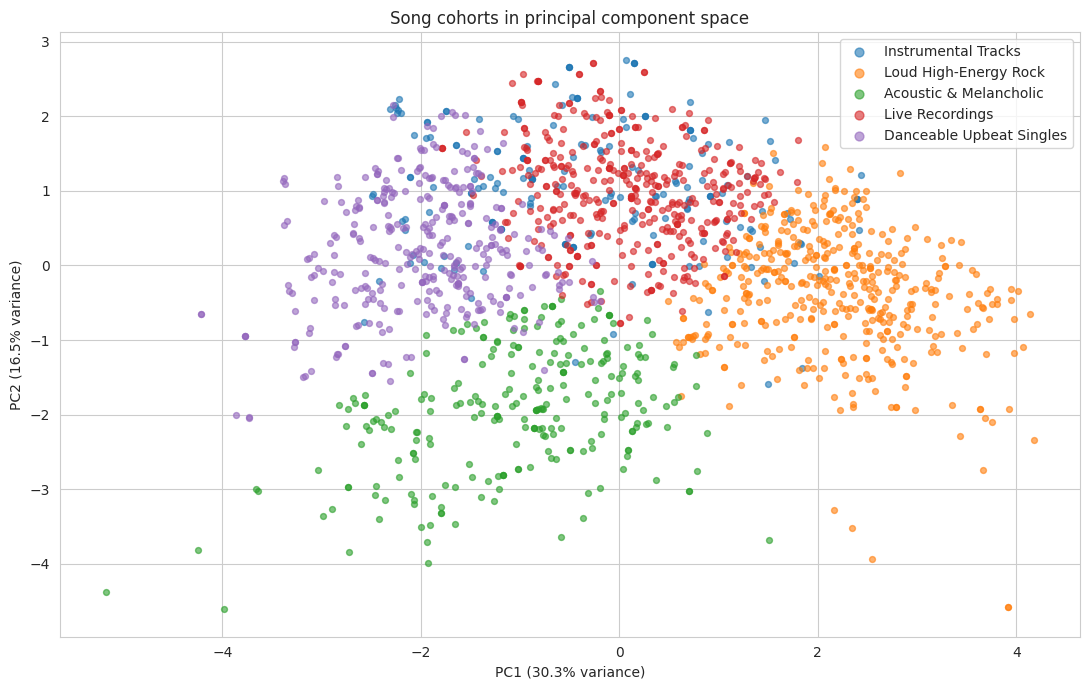

In [21]:
pca2 = PCA(n_components=2, random_state=RANDOM_STATE)
X_2d = pca2.fit_transform(X_scaled)

plt.figure(figsize=(11, 7))
palette = sns.color_palette('tab10', K)

for i, name in enumerate(df['cohort'].unique()):
    mask = df['cohort'] == name
    plt.scatter(X_2d[mask, 0], X_2d[mask, 1],
                label=name, alpha=0.6, s=18, color=palette[i])

plt.xlabel(f"PC1 ({pca2.explained_variance_ratio_[0]*100:.1f}% variance)")
plt.ylabel(f"PC2 ({pca2.explained_variance_ratio_[1]*100:.1f}% variance)")
plt.title('Song cohorts in principal component space')
plt.legend(markerscale=1.5)
plt.tight_layout()
plt.show()


**7.2 Finding**

The plot uses the first two components, which together explain 46.8% of the variation.

The groups sit in different areas rather than mixing randomly, but the edges between them are gradual. Loud High-Energy Rock sits right, Acoustic & Melancholic at the bottom, Danceable Upbeat Singles left.

This matches the silhouette of 0.146: real groups, but overlapping.

A few songs sit far from the rest. Unusual combinations, not errors, and too few to change anything.


### Section 7 summary

Popularity and release year were left out of the clustering and used only to check it. That makes the comparison fair.

The groups are not based on era. Median years run from 1967 to 2016, and each group draws songs from the whole career.

The strongest result: the largest group, Loud High-Energy Rock with 431 songs, has no popular songs at all. The smaller Acoustic & Melancholic group has the highest share at 5.5%.


## Conclusion

This project grouped songs into cohorts using Spotify's audio features and looked at what drives popularity.

The data needed almost no cleaning. All 1,610 rows were complete, no track IDs repeated, and the features were already on the right scale. The one real question was 656 repeated song names, separate live versions and remasters rather than errors. "Brown Sugar - Live" appears on 15 different concert albums. Keeping them mattered: deleting them would have removed 60% of the data.

Sticky Fingers (Remastered) is the clear first album to recommend, leading every measure with an average popularity of 53.3 and 60% of its tracks above 50. Second place depends on how you count. Some Girls leads on average and on share, while Exile On Main Street collects more hits simply because it has 18 tracks instead of 10. Share is the fairer measure, which points to Sticky Fingers and Some Girls.

Nothing about how a song sounds predicts its popularity. The strongest link is liveness at −0.21 and everything else is under ±0.16. The trend over time is close to flat, at −0.08 points per year.

Clustering gave five groups: Loud High-Energy Rock (431), Live Recordings (411), Danceable Upbeat Singles (332), Acoustic & Melancholic (256) and Instrumental Tracks (180). Six components were needed to explain 80% of the variation.

The most interesting result came from the check afterwards. The groups cover the whole career, median years from 1967 to 2016, so they are based on how songs sound, not when they came out. And the biggest group has no popular songs at all, while the smaller Acoustic & Melancholic group has the highest share at 5.5%. The band's loudest and most energetic material is not what attracts the most streaming activity.

In practice the five groups work as recommendation buckets. Keeping a session inside one group gives songs that fit together, and starting new listeners on the acoustic and danceable groups gives the best chance they hear something familiar.
